# 10 · Haze: smoke from fires upwind

> **What and why**
>
> - Smoke from Sumatra and Borneo crosses borders. In bad years it closes schools and airports in Malaysia and Singapore.
> - For eight cities we ask how much of the fine particle pollution (PM2.5) in the fire season comes from fires in each source region.
> - Smoke adds up, so the model is simple: a normal level for the month plus an amount for every 1,000 hotspots in Sumatra and in Borneo.
> - We fit it on 2002 to 2025 with NASA's bias corrected MERRA-2 PM2.5 and test it on years left out.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
import json
from matplotlib.colors import LogNorm, Normalize, TwoSlopeNorm
from fireharmony import climate as K, drivers as D
MODELS = REPO / 'models'
BORDERS = con.execute(f"SELECT ST_AsText(ST_Simplify(geom, 0.15)) AS w FROM ST_Read('{FE.ne_source('ne_10m_admin_0_countries')}')").df().w
hz = json.loads((MODELS / 'haze.json').read_text())
h = pd.read_parquet(K.out('haze_city_month.parquet'))
season = h[h.mo.between(*hz['season_months'])]

## 1. The model of each city

In [2]:
rows = []
for c, m in hz['cities'].items():
    s = season[(season.city == c) & season.yr.between(*hz['fit_years'])]
    k = m['ug_per_1000_hotspots']
    smoke_s, smoke_b = (k['sumatra'] * s.sumatra).sum(), (k['borneo'] * s.borneo).sum()
    rows.append({'city': c, 'R2 on years left out': m['r2_cv'], 'ug/m3 per 1,000 hotspots, Sumatra': k['sumatra'],
                 'ug/m3 per 1,000 hotspots, Borneo': k['borneo'], 'smoke share from Sumatra': smoke_s / max(smoke_s + smoke_b, 1e-9),
                 'mean PM2.5 Jul to Nov': s.pm25_cnn.mean()})
pd.DataFrame(rows).set_index('city').round(3)

,R2 on years left out,"ug/m3 per 1,000 hotspots, Sumatra","ug/m3 per 1,000 hotspots, Borneo",smoke share from Sumatra,mean PM2.5 Jul to Nov
city,,,,,
Kuala Lumpur,0.793,0.217,0.018,0.882,19.521
George Town,0.920,0.061,0.000,1.000,23.191
Johor Bahru,0.812,0.128,0.111,0.423,19.891
Kuching,0.507,0.000,0.095,0.000,10.085
Kota Kinabalu,0.781,0.033,0.065,0.246,7.477
Singapore,0.812,0.128,0.111,0.423,19.891
Pekanbaru,0.867,0.104,0.000,1.000,18.859
Palangka Raya,0.703,0.000,0.232,0.000,11.625


## 2. Kuala Lumpur, every fire season

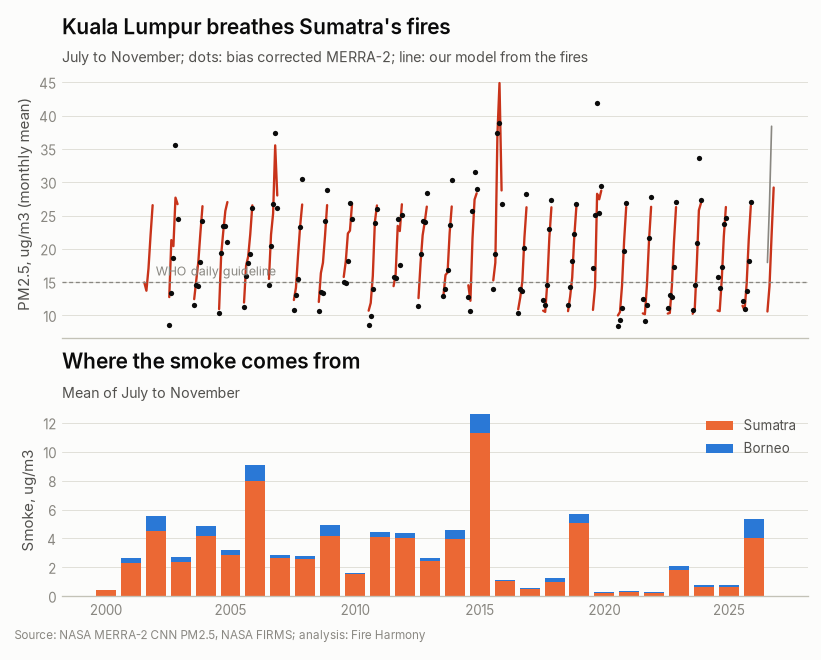

In [3]:
kl = season[season.city == 'Kuala Lumpur']
k = hz['cities']['Kuala Lumpur']['ug_per_1000_hotspots']
fig, axes = plt.subplots(2, 1, figsize=fh.SIZE['full_tall'], sharex=True, gridspec_kw={'height_ratios': [1.4, 1]})
ax = axes[0]
for yr, g in kl.groupby('yr'):
    tt = g.yr + (g.mo - 0.5) / 12
    ax.plot(tt, g.pm25_model, color=fh.EMBER[5], lw=1.4)
    ax.scatter(tt, g.pm25_cnn, s=10, color=fh.INK, zorder=3)
    if yr == 2026:
        ax.plot(tt, g.pm25_merra2, color=fh.MUTED, lw=1.0)
ax.axhline(hz['who_daily_guideline'], color=fh.MUTED, lw=0.8, ls=(0, (3, 2)))
ax.text(2002, hz['who_daily_guideline'] + 1, 'WHO daily guideline', fontsize=7.5, color=fh.MUTED)
fh.clean(ax); ax.set_ylabel('PM2.5, ug/m3 (monthly mean)')
fh.title(ax, 'Kuala Lumpur breathes Sumatra\'s fires', 'July to November; dots: bias corrected MERRA-2; line: our model from the fires')
ax = axes[1]
yy = kl.groupby('yr').agg(s=('sumatra', 'mean'), b=('borneo', 'mean'))
ax.bar(yy.index, k['sumatra'] * yy.s, color=fh.SENSOR['VIIRS_SNPP'], width=0.8, label='Sumatra')
ax.bar(yy.index, k['borneo'] * yy.b, bottom=k['sumatra'] * yy.s, color=fh.SENSOR['MODIS'], width=0.8, label='Borneo')
fh.clean(ax); ax.set_ylabel('Smoke, ug/m3'); ax.legend(frameon=False, fontsize=8)
fh.title(ax, 'Where the smoke comes from', 'Mean of July to November')
fh.source(fig, 'Source: NASA MERRA-2 CNN PM2.5, NASA FIRMS; analysis: Fire Harmony')
fig.get_layout_engine().set(rect=(0, 0.03, 1, 1))
fh.save(fig, FIG / 'fig18_haze_kuala_lumpur')

## 3. Three fire seasons compared: 2015, 2019 and 2026

In [4]:
cmp = season[season.yr.isin([2015, 2019, 2026]) & season.mo.between(8, 10)]
cmp.pivot_table(index='city', columns='yr', values=['pm25_cnn', 'pm25_model', 'smoke_model'], aggfunc='mean').round(1)

pm25_cnn       pm25_model             smoke_model            
yr                2015  2019       2015  2019  2026        2015  2019  2026
city                                                                       
George Town       24.0  27.4       23.7  21.2  20.6         4.6   2.1   1.4
Johor Bahru       34.5  31.7       35.6  23.8  27.2        21.6   9.8  13.3
Kota Kinabalu     13.2  11.5       14.7   9.5  11.9         9.5   4.3   6.8
Kuala Lumpur      31.8  30.7       33.3  23.3  21.9        18.3   8.3   6.9
Kuching           14.0  13.5       18.4  12.7  16.9        10.3   4.7   8.8
Palangka Raya     24.3  17.5       30.4  16.6  26.7        25.2  11.5  21.6
Pekanbaru         20.5  23.2       23.0  18.8  17.7         7.8   3.5   2.4
Singapore         34.5  31.7       35.6  23.8  27.2        21.6   9.8  13.3

In [5]:
season[season.yr.isin([2015, 2019, 2026]) & (season.city == 'Kuala Lumpur')][['yr', 'mo', 'sumatra', 'borneo', 'pm25_cnn', 'pm25_model', 'pm25_merra2', 'days_over_who', 'days_over_50']].round(1)

,yr,mo,sumatra,borneo,pm25_cnn,pm25_model,pm25_merra2,days_over_who,days_over_50
176,2015,7,24.1,12.6,14.0,15.3,32.900002,8.0,0.0
177,2015,8,31.7,62.7,19.2,17.9,28.900000,16.0,0.0
178,2015,9,94.2,133.7,37.3,37.2,64.699997,28.0,4.0
179,2015,10,99.0,129.5,38.9,44.9,61.500000,28.0,7.0
180,2015,11,11.1,8.6,26.8,28.8,13.300000,29.0,0.0
224,2019,7,4.4,4.7,17.1,10.8,22.500000,17.0,0.0
225,2019,8,17.7,29.3,25.0,14.3,33.500000,29.0,0.0
226,2019,9,55.7,105.7,41.9,28.3,72.900002,29.0,10.0
227,2019,10,28.6,13.2,25.3,27.4,21.900000,29.0,0.0
228,2019,11,10.8,11.5,29.4,28.7,15.100000,30.0,0.0


> **Key findings**
>
> - Fires upwind explain 51 to 92% of the ups and downs of fire season PM2.5 in the eight cities, on years left out.
> - Kuala Lumpur breathes Sumatra: 88% of its smoke from fires comes from there. Johor Bahru and Singapore get both (42% from Sumatra, 58% from Borneo). Kuching and Palangka Raya get only Borneo smoke.
> - Every 1,000 more hotspots in Sumatra add about 0.22 micrograms per cubic metre to the monthly mean in Kuala Lumpur.
> - In September and October 2015, smoke added about 23 micrograms per cubic metre to Kuala Lumpur's monthly mean, and the city had 28 days above the WHO daily guideline in each month.
> - In 2026 the fires burned mostly in Borneo. Kuala Lumpur's smoke from August to October (7 micrograms per cubic metre) stayed below 2019 (8) and far below 2015 (18). Palangka Raya (22) came close to 2015 (25).
> - For 2026 there is no bias corrected PM2.5 yet. Uncorrected MERRA-2 also shows less haze in Kuala Lumpur in September 2026 (38) than in 2015 (65) and 2019 (73).